In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel('../data/transaction_data.xlsx')

shape_log = []

def log_shape(df, label):
    """Log current row/column count with a descriptive label."""
    shape_log.append({
        'step'   : label,
        'rows'   : len(df),
        'columns': df.shape[1]
    })
    print(f"[{label}] rows: {len(df):,}  |  columns: {df.shape[1]}")

log_shape(df, "01 - raw load")

[01 - raw load] rows: 264,836  |  columns: 8


In [3]:
display(df.head(10))

,DATE,STORE_NBR,LYLTY_CARD_NBR,TXN_ID,PROD_NBR,PROD_NAME,PROD_QTY,TOT_SALES
0,43390,1,1000,1,5,Natural Chip Compny SeaSalt175g,2,6.0
1,43599,1,1307,348,66,CCs Nacho Cheese 175g,3,6.3
2,43605,1,1343,383,61,Smiths Crinkle Cut Chips Chicken 170g,2,2.9
3,43329,2,2373,974,69,Smiths Chip Thinly S/Cream&Onion 175g,5,15.0
4,43330,2,2426,1038,108,Kettle Tortilla ChpsHny&Jlpno Chili 150g,3,13.8
5,43604,4,4074,2982,57,Old El Paso Salsa Dip Tomato Mild 300g,1,5.1
6,43601,4,4149,3333,16,Smiths Crinkle Chips Salt & Vinegar 330g,1,5.7
7,43601,4,4196,3539,24,Grain Waves Sweet Chilli 210g,1,3.6
8,43332,5,5026,4525,42,Doritos Corn Chip Mexican Jalapeno 150g,1,3.9
9,43330,7,7150,6900,52,Grain Waves Sour Cream&Chives 210G,2,7.2


In [4]:
df.isnull().sum()

DATE              0
STORE_NBR         0
LYLTY_CARD_NBR    0
TXN_ID            0
PROD_NBR          0
PROD_NAME         0
PROD_QTY          0
TOT_SALES         0
dtype: int64

- no null values

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 264836 entries, 0 to 264835
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   DATE            264836 non-null  int64  
 1   STORE_NBR       264836 non-null  int64  
 2   LYLTY_CARD_NBR  264836 non-null  int64  
 3   TXN_ID          264836 non-null  int64  
 4   PROD_NBR        264836 non-null  int64  
 5   PROD_NAME       264836 non-null  object 
 6   PROD_QTY        264836 non-null  int64  
 7   TOT_SALES       264836 non-null  float64
dtypes: float64(1), int64(6), object(1)
memory usage: 16.2+ MB


In [6]:
# clean column names

df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
display(df.head())

,date,store_nbr,lylty_card_nbr,txn_id,prod_nbr,prod_name,prod_qty,tot_sales
0,43390,1,1000,1,5,Natural Chip Compny SeaSalt175g,2,6.0
1,43599,1,1307,348,66,CCs Nacho Cheese 175g,3,6.3
2,43605,1,1343,383,61,Smiths Crinkle Cut Chips Chicken 170g,2,2.9
3,43329,2,2373,974,69,Smiths Chip Thinly S/Cream&Onion 175g,5,15.0
4,43330,2,2426,1038,108,Kettle Tortilla ChpsHny&Jlpno Chili 150g,3,13.8


- date is on a different format
- values are messy under the prod_name column

In [7]:
df['date'] = pd.to_datetime(df['date'],unit='D', origin='1899-12-30')
display(df.head())

,date,store_nbr,lylty_card_nbr,txn_id,prod_nbr,prod_name,prod_qty,tot_sales
0,2018-10-17,1,1000,1,5,Natural Chip Compny SeaSalt175g,2,6.0
1,2019-05-14,1,1307,348,66,CCs Nacho Cheese 175g,3,6.3
2,2019-05-20,1,1343,383,61,Smiths Crinkle Cut Chips Chicken 170g,2,2.9
3,2018-08-17,2,2373,974,69,Smiths Chip Thinly S/Cream&Onion 175g,5,15.0
4,2018-08-18,2,2426,1038,108,Kettle Tortilla ChpsHny&Jlpno Chili 150g,3,13.8


In [8]:
# check for duplicates
print(df.duplicated().sum())

1


In [9]:
df = df.drop_duplicates()

log_shape(df, "02 - dropped duplicates")

[02 - dropped duplicates] rows: 264,835  |  columns: 8


In [10]:
df.describe(include='number')

,store_nbr,lylty_card_nbr,txn_id,prod_nbr,prod_qty,tot_sales
count,264835.000000,2.648350e+05,2.648350e+05,264835.000000,264835.000000,264835.000000
mean,135.080216,1.355496e+05,1.351584e+05,56.583201,1.907308,7.304205
std,76.784306,8.058011e+04,7.813316e+04,32.826692,0.643655,3.083231
min,1.000000,1.000000e+03,1.000000e+00,1.000000,1.000000,1.500000
25%,70.000000,7.002100e+04,6.760100e+04,28.000000,2.000000,5.400000
50%,130.000000,1.303580e+05,1.351380e+05,56.000000,2.000000,7.400000
75%,203.000000,2.030945e+05,2.027015e+05,85.000000,2.000000,9.200000
max,272.000000,2.373711e+06,2.415841e+06,114.000000,200.000000,650.000000


- values of 200 and 650 are glaring outliers under the prod_qty and tot_sales column

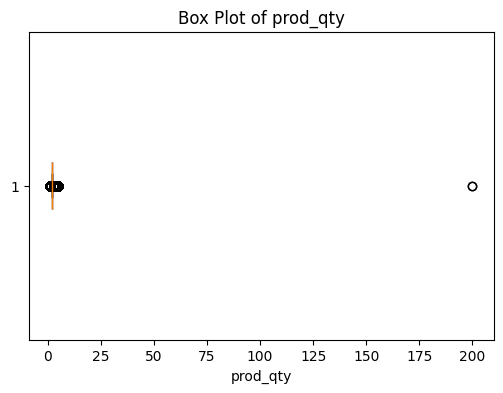

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.boxplot(df['prod_qty'], patch_artist=True, vert=False)
plt.title('Box Plot of prod_qty')
plt.xlabel('prod_qty')
plt.show()

In [12]:
outlier = df.loc[df['prod_qty']==200]
print(outlier)

            date  store_nbr  lylty_card_nbr  txn_id  prod_nbr  \
69762 2018-08-19        226          226000  226201         4   
69763 2019-05-20        226          226000  226210         4   

                              prod_name  prod_qty  tot_sales  
69762  Dorito Corn Chp     Supreme 380g       200      650.0  
69763  Dorito Corn Chp     Supreme 380g       200      650.0  


- WHOLESALE purchase; the outlier is made by the same person, buying the same product in bulk, 9 months apart.
- this could very well be a valid transaction, but is not part of the scope; retail chip performance

In [13]:
df = df.loc[df['prod_qty'] != 200]
log_shape(df, "03 - dropped wholesale quantity outlier")

[03 - dropped wholesale quantity outlier] rows: 264,833  |  columns: 8


In [14]:
# create a clean product name column for easier brand and flavor extraction
df["clean_prod_name"] = df["prod_name"].str.lower().str.replace(r"[^a-z0-9\s]", "", regex=True).str.strip()
df[["prod_name", "clean_prod_name"]].head()

log_shape(df, "04 - included a clean product column")
df.head()

[04 - included a clean product column] rows: 264,833  |  columns: 9


,date,store_nbr,lylty_card_nbr,txn_id,prod_nbr,prod_name,prod_qty,tot_sales,clean_prod_name
0,2018-10-17,1,1000,1,5,Natural Chip Compny SeaSalt175g,2,6.0,natural chip compny seasalt175g
1,2019-05-14,1,1307,348,66,CCs Nacho Cheese 175g,3,6.3,ccs nacho cheese 175g
2,2019-05-20,1,1343,383,61,Smiths Crinkle Cut Chips Chicken 170g,2,2.9,smiths crinkle cut chips chicken 170g
3,2018-08-17,2,2373,974,69,Smiths Chip Thinly S/Cream&Onion 175g,5,15.0,smiths chip thinly screamonion 175g
4,2018-08-18,2,2426,1038,108,Kettle Tortilla ChpsHny&Jlpno Chili 150g,3,13.8,kettle tortilla chpshnyjlpno chili 150g


In [15]:
# first line of cleaning the column

df["clean_prod_name"] = (
    df["prod_name"]
    .str.lower()

    # 1. Insert space between letters and numbers
    .str.replace(r"([a-z])(\d)", r"\1 \2", regex=True)
    .str.replace(r"(\d)([a-z])", r"\1 \2", regex=True)

    # 2. Remove special characters
    .str.replace(r"[^a-z0-9\s]", " ", regex=True)

    # 3. Normalize multiple spaces
    .str.replace(r"\s+", " ", regex=True)

    # 4. Trim
    .str.strip()
)

df[["prod_name", "clean_prod_name"]].head(10)

,prod_name,clean_prod_name
0,Natural Chip Compny SeaSalt175g,natural chip compny seasalt 175 g
1,CCs Nacho Cheese 175g,ccs nacho cheese 175 g
2,Smiths Crinkle Cut Chips Chicken 170g,smiths crinkle cut chips chicken 170 g
3,Smiths Chip Thinly S/Cream&Onion 175g,smiths chip thinly s cream onion 175 g
4,Kettle Tortilla ChpsHny&Jlpno Chili 150g,kettle tortilla chpshny jlpno chili 150 g
5,Old El Paso Salsa Dip Tomato Mild 300g,old el paso salsa dip tomato mild 300 g
6,Smiths Crinkle Chips Salt & Vinegar 330g,smiths crinkle chips salt vinegar 330 g
7,Grain Waves Sweet Chilli 210g,grain waves sweet chilli 210 g
8,Doritos Corn Chip Mexican Jalapeno 150g,doritos corn chip mexican jalapeno 150 g
9,Grain Waves Sour Cream&Chives 210G,grain waves sour cream chives 210 g


In [16]:
# extracted net weight from clean_prod_name and designated it as a new column

df["net_weight"] = df["clean_prod_name"].str.extract(
    r"(\d{2,3})\s+g\b",
    expand=False
)
#convert to numeric value
df["net_weight"] = pd.to_numeric(df["net_weight"])

log_shape(df, "05 - created a net_weight column extracted from clean_prod_name")

df[["prod_name", "clean_prod_name", "net_weight"]].head(10)

[05 - created a net_weight column extracted from clean_prod_name] rows: 264,833  |  columns: 10


,prod_name,clean_prod_name,net_weight
0,Natural Chip Compny SeaSalt175g,natural chip compny seasalt 175 g,175
1,CCs Nacho Cheese 175g,ccs nacho cheese 175 g,175
2,Smiths Crinkle Cut Chips Chicken 170g,smiths crinkle cut chips chicken 170 g,170
3,Smiths Chip Thinly S/Cream&Onion 175g,smiths chip thinly s cream onion 175 g,175
4,Kettle Tortilla ChpsHny&Jlpno Chili 150g,kettle tortilla chpshny jlpno chili 150 g,150
5,Old El Paso Salsa Dip Tomato Mild 300g,old el paso salsa dip tomato mild 300 g,300
6,Smiths Crinkle Chips Salt & Vinegar 330g,smiths crinkle chips salt vinegar 330 g,330
7,Grain Waves Sweet Chilli 210g,grain waves sweet chilli 210 g,210
8,Doritos Corn Chip Mexican Jalapeno 150g,doritos corn chip mexican jalapeno 150 g,150
9,Grain Waves Sour Cream&Chives 210G,grain waves sour cream chives 210 g,210


In [17]:
# return net_weight entries that contain 'g' to double-check the extraction

df.loc[pd.to_numeric(df["net_weight"], errors="coerce").isna()]

,date,store_nbr,lylty_card_nbr,txn_id,prod_nbr,prod_name,prod_qty,tot_sales,clean_prod_name,net_weight


In [18]:
# list the most common first words in the clean product name to identify brands

first_words = df["clean_prod_name"].str.split().str[0]
first_word_counts = first_words.value_counts()

first_word_counts.head(50)  # display the top 50 most common first words

clean_prod_name
kettle        41288
smiths        28859
pringles      25102
doritos       24962
thins         14075
rrd           11894
infuzions     11057
ww            10320
cobs           9693
tostitos       9471
twisties       9454
old            9324
tyrrells       6442
grain          6272
natural        6050
red            5885
cheezels       4603
ccs            4551
woolworths     4437
dorito         3183
infzns         3144
smith          2963
cheetos        2927
snbts          1576
burger         1564
grnwves        1468
sunbites       1432
ncc            1419
french         1418
Name: count, dtype: int64

In [19]:
# create a brand mapping dictionary from the most common first words

brand_map = {
    # Unambiguous single-token brands
    "kettle"    : "Kettle",
    "smiths"    : "Smith's",
    "smith"     : "Smith's",      # abbreviated variant
    "pringles"  : "Pringles",
    "doritos"   : "Doritos",
    "dorito"    : "Doritos",      # abbreviated variant
    "thins"     : "Thins",
    "infuzions" : "Infuzions",
    "infzns"    : "Infuzions",    # abbreviated variant
    "ww"        : "Woolworths",
    "woolworths": "Woolworths",
    "cobs"      : "Cobs",
    "tostitos"  : "Tostitos",
    "twisties"  : "Twisties",
    "tyrrells"  : "Tyrrells",
    "cheezels"  : "Cheezels",
    "ccs"       : "CCs",          
    "cheetos"   : "Cheetos",
    "snbts"     : "Sunbites",
    "sunbites"  : "Sunbites",
}

In [20]:
def fallback_brand(text):
    text = str(text)

    # Multi-word brand names — checked by substring, not first token
    if "red rock" in text or "rrd" in text:
        return "Red Rock Deli"
    if "grain waves" in text or "grnwves" in text:
        return "Grain Waves"
    if "natural chip" in text or "ncc" in text:
        return "Natural Chip Company"
    if "burger rings" in text:
        return "Burger Rings"
    if "french fries" in text:
        return "French Fries"

    return "Unknown"

In [21]:
#apply two-pass logic

def get_primary_brand(text):
    tokens = str(text).split()
    for t in tokens:
        if t in brand_map:
            return brand_map[t]
    return "Unknown"

df["brand"] = df["clean_prod_name"].apply(get_primary_brand)

# Second pass: fill remaining Unknowns using fallback substring matching
mask = df["brand"] == "Unknown"
df.loc[mask, "brand"] = df.loc[mask, "clean_prod_name"].apply(fallback_brand)

log_shape(df, "06 created a brands column")

[06 created a brands column] rows: 264,833  |  columns: 11


In [22]:
# check for any remaining unlabeled brands due to unrecognized first words or substrings

unknown_df = df[df["brand"] == "Unknown"][["prod_name", "clean_prod_name", "brand"]]

print(f"Unknown brand rows: {len(unknown_df)}")

if len(unknown_df) > 0:
    print("\nSample of unresolved rows:")
    print(unknown_df["prod_name"].value_counts().head(20).to_string())

Unknown brand rows: 9324

Sample of unresolved rows:
prod_name
Old El Paso Salsa   Dip Chnky Tom Ht300g    3125
Old El Paso Salsa   Dip Tomato Med 300g     3114
Old El Paso Salsa   Dip Tomato Mild 300g    3085


- 'Old' is ambigouos on its own, but is indeed a brand
- this analysis would focus mainly on chips; dips are out of scope
- 'Salsa' and 'Dip' are keywords of products to exclude

In [23]:
# drop salsa and dip products

df_salsa_dip = df[df["clean_prod_name"].str.contains(
    "salsa|dip",
    case=False,
    na=False
)].drop(columns=["prod_name"]).copy()

df = df[~df["clean_prod_name"].str.contains(
    "salsa|dip",
    case=False,
    na=False
)].drop(columns=["prod_name"]).copy()

display(df.head(10))

log_shape(df, "07 - dropped salsa/dip products; dropped old prod_name column")

,date,store_nbr,lylty_card_nbr,txn_id,prod_nbr,prod_qty,tot_sales,clean_prod_name,net_weight,brand
0,2018-10-17,1,1000,1,5,2,6.0,natural chip compny seasalt 175 g,175,Natural Chip Company
1,2019-05-14,1,1307,348,66,3,6.3,ccs nacho cheese 175 g,175,CCs
2,2019-05-20,1,1343,383,61,2,2.9,smiths crinkle cut chips chicken 170 g,170,Smith's
3,2018-08-17,2,2373,974,69,5,15.0,smiths chip thinly s cream onion 175 g,175,Smith's
4,2018-08-18,2,2426,1038,108,3,13.8,kettle tortilla chpshny jlpno chili 150 g,150,Kettle
6,2019-05-16,4,4149,3333,16,1,5.7,smiths crinkle chips salt vinegar 330 g,330,Smith's
7,2019-05-16,4,4196,3539,24,1,3.6,grain waves sweet chilli 210 g,210,Grain Waves
8,2018-08-20,5,5026,4525,42,1,3.9,doritos corn chip mexican jalapeno 150 g,150,Doritos
9,2018-08-18,7,7150,6900,52,2,7.2,grain waves sour cream chives 210 g,210,Grain Waves
10,2019-05-17,7,7215,7176,16,1,5.7,smiths crinkle chips salt vinegar 330 g,330,Smith's


[07 - dropped salsa/dip products; dropped old prod_name column] rows: 245,301  |  columns: 10


In [24]:
display(df["clean_prod_name"].unique().tolist())

['natural chip compny seasalt 175 g',
 'ccs nacho cheese 175 g',
 'smiths crinkle cut chips chicken 170 g',
 'smiths chip thinly s cream onion 175 g',
 'kettle tortilla chpshny jlpno chili 150 g',
 'smiths crinkle chips salt vinegar 330 g',
 'grain waves sweet chilli 210 g',
 'doritos corn chip mexican jalapeno 150 g',
 'grain waves sour cream chives 210 g',
 'kettle sensations siracha lime 150 g',
 'twisties cheese 270 g',
 'ww crinkle cut chicken 175 g',
 'thins chips light tangy 175 g',
 'ccs original 175 g',
 'burger rings 220 g',
 'ncc sour cream garden chives 175 g',
 'doritos corn chip southern chicken 150 g',
 'cheezels cheese box 125 g',
 'smiths crinkle original 330 g',
 'infzns crn crnchers tangy gcamole 110 g',
 'kettle sea salt and vinegar 175 g',
 'smiths chip thinly cut original 175 g',
 'kettle original 175 g',
 'red rock deli thai chilli lime 150 g',
 'pringles sthrn friedchicken 134 g',
 'pringles sweet spcy bbq 134 g',
 'thins chips originl saltd 175 g',
 'red rock d

In [25]:
# final check for uncatched brands

display(df.loc[df["brand"]=='Unknown'])

,date,store_nbr,lylty_card_nbr,txn_id,prod_nbr,prod_qty,tot_sales,clean_prod_name,net_weight,brand


In [26]:
#quick glance at the brands

df["brand"].unique().tolist()

['Natural Chip Company',
 'CCs',
 "Smith's",
 'Kettle',
 'Grain Waves',
 'Doritos',
 'Twisties',
 'Woolworths',
 'Thins',
 'Burger Rings',
 'Cheezels',
 'Infuzions',
 'Red Rock Deli',
 'Pringles',
 'Tyrrells',
 'Cobs',
 'French Fries',
 'Tostitos',
 'Cheetos',
 'Sunbites']

- looks good! now proceed with the net_weight column

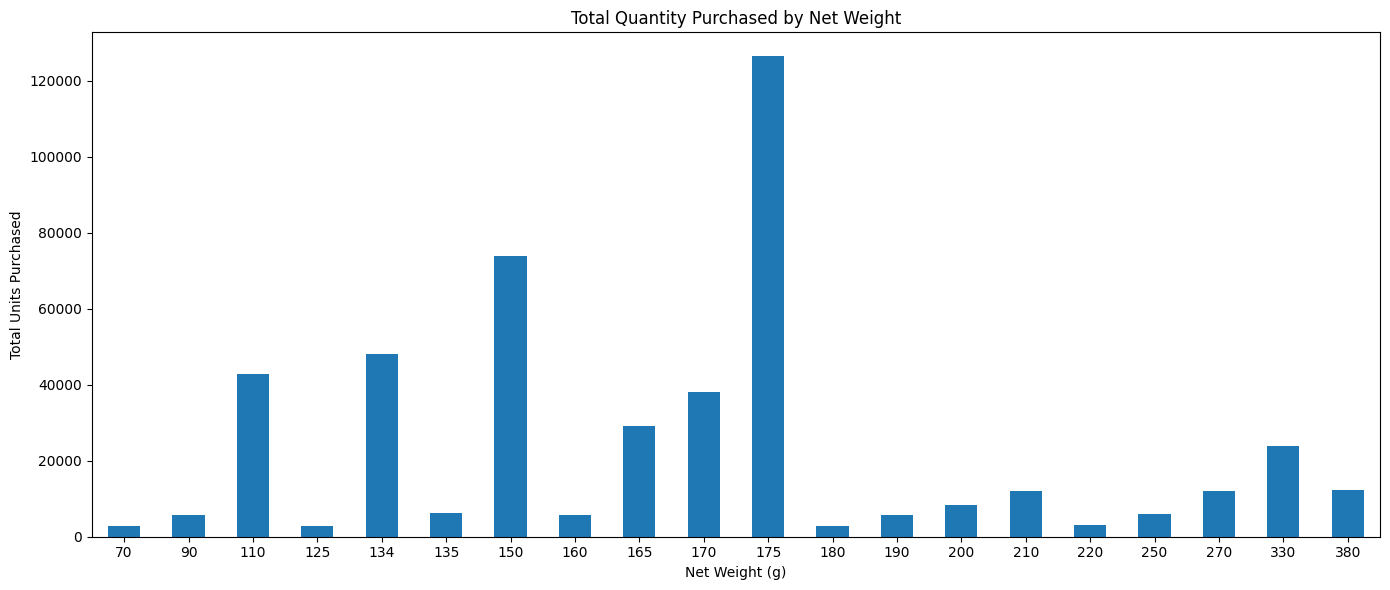

In [27]:
# look at the distribution of net weight across transactions

df.groupby("net_weight")["prod_qty"].sum().sort_index().plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Total Quantity Purchased by Net Weight")
plt.xlabel("Net Weight (g)")
plt.ylabel("Total Units Purchased")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [28]:
# look at product configurations that come at the most popular pack size

df[df['net_weight'] == 175]['clean_prod_name'].unique()

array(['natural chip compny seasalt 175 g', 'ccs nacho cheese 175 g',
       'smiths chip thinly s cream onion 175 g',
       'ww crinkle cut chicken 175 g', 'thins chips light tangy 175 g',
       'ccs original 175 g', 'ncc sour cream garden chives 175 g',
       'kettle sea salt and vinegar 175 g',
       'smiths chip thinly cut original 175 g', 'kettle original 175 g',
       'thins chips originl saltd 175 g',
       'smiths thinly swt chli s cream 175 g', 'kettle chilli 175 g',
       'natural chipco hony soy chckn 175 g',
       'smiths thinly cut roast chicken 175 g',
       'kettle mozzarella basil pesto 175 g',
       'kettle honey soy chicken 175 g',
       'thins chips seasonedchicken 175 g',
       'kettle sweet chilli and sour cream 175 g',
       'natural chip co tmato hrb spce 175 g',
       'french fries potato chips 175 g',
       'thins potato chips hot spicy 175 g',
       'smiths chip thinly cutsalt vinegr 175 g',
       'tostitos lightly salted 175 g', 'thins chips 

In [29]:
# compare the number of unique products at the most popular pack size (175g) and a moderately performing pack size (110g)

count_175 = df[df['net_weight'] == 175]['clean_prod_name'].nunique()
count_110 = df[df['net_weight'] == 110]['clean_prod_name'].nunique()

print("net_weight == 175:", count_175)
print("net_weight == 110:", count_110)

net_weight == 175: 30
net_weight == 110: 7


- the chip's pack size popularity is also influenced by the number of offerings in that weight
- the 100g category appear in less transactions, due to less offerings in general

In [30]:
# count the number of transactions per date

transactions_per_date = df.groupby("date").size()
print(transactions_per_date)

date
2018-07-01    657
2018-07-02    647
2018-07-03    667
2018-07-04    667
2018-07-05    654
             ... 
2019-06-26    657
2019-06-27    666
2019-06-28    670
2019-06-29    695
2019-06-30    698
Length: 364, dtype: int64


- only 364 recorded dates, let's zoom in

<Axes: >

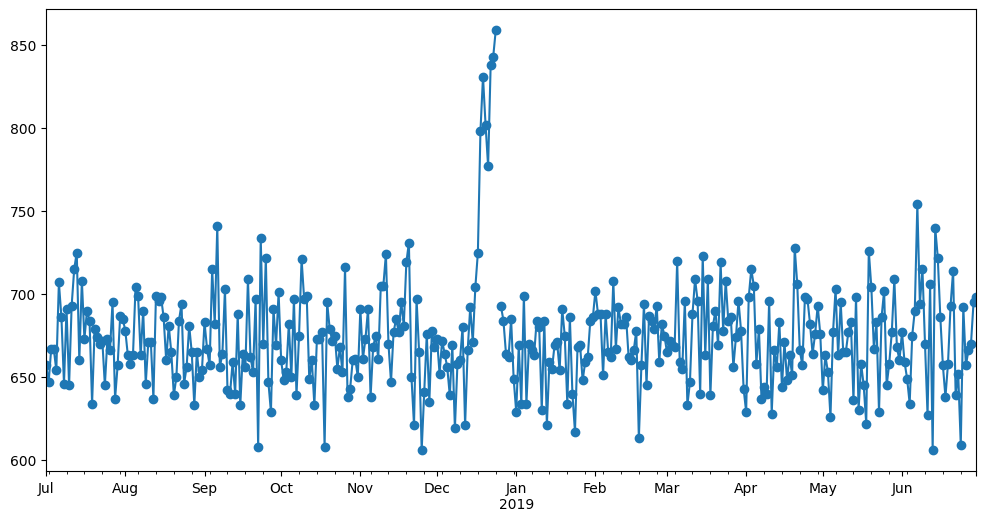

In [31]:
# plot the number of transactions per date as a line chart

transactions_per_date.reindex(
    pd.date_range(
        transactions_per_date.index.min(),
        transactions_per_date.index.max(),
        freq="D"
    )
).plot(kind="line", marker="o", figsize=(12, 6))

- a clear break point between Dec and Jan

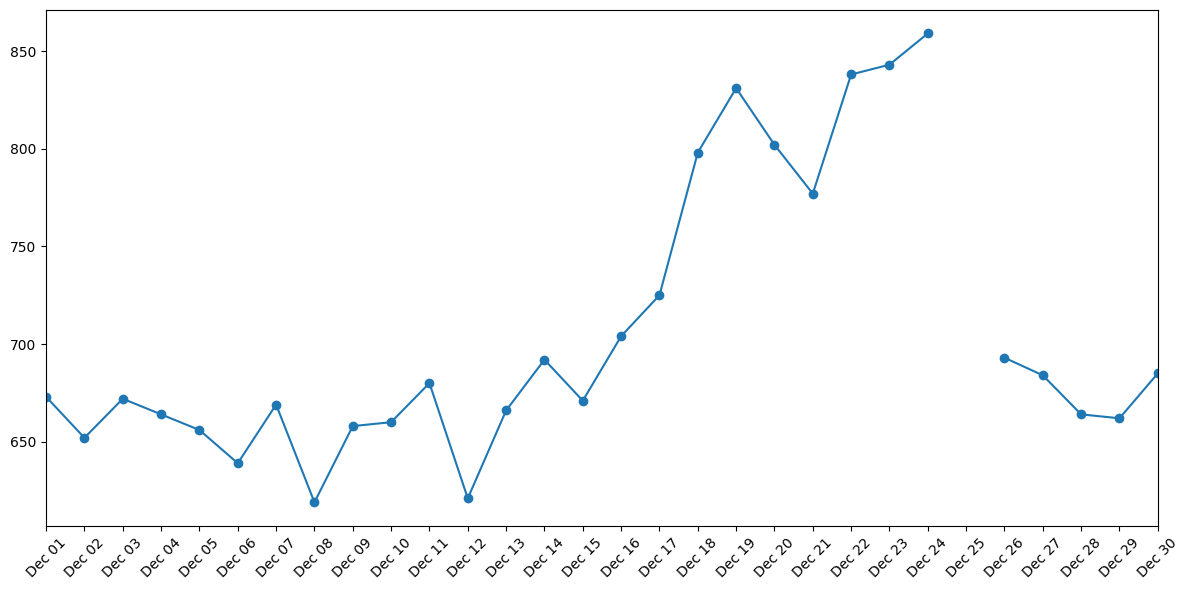

In [32]:
import matplotlib.dates as mdates

df_dec = df[df["date"].dt.month == 12].copy()

transactions_per_date_dec = (
    df_dec.groupby(df_dec["date"].dt.normalize()).size()
)

full_days = pd.date_range("2018-12-01", "2018-12-30", freq="D")

ax = transactions_per_date_dec.reindex(full_days).plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

*a normal upwards trend towards the Holiday* with its highest peak at the 24th
no recorded transaction on the 25th as the stores are closed; makes sense!

In [33]:
# ── CLEANING SUMMARY ──────────────────────────────────────────────────────────
print(pd.DataFrame(shape_log).to_string(index=False))

                                                           step   rows  columns
                                                  01 - raw load 264836        8
                                        02 - dropped duplicates 264835        8
                        03 - dropped wholesale quantity outlier 264833        8
                           04 - included a clean product column 264833        9
05 - created a net_weight column extracted from clean_prod_name 264833       10
                                     06 created a brands column 264833       11
  07 - dropped salsa/dip products; dropped old prod_name column 245301       10


# with the cleaned and logically-sound transaction dataset, let's now look at the customer dataset

In [34]:
df_customer = pd.read_csv('../data/purchase_behavior.csv')
display(df_customer.head(10))

log_shape(df_customer, "08 raw load of customer dataset")

,LYLTY_CARD_NBR,LIFESTAGE,PREMIUM_CUSTOMER
0,1000,YOUNG SINGLES/COUPLES,Premium
1,1002,YOUNG SINGLES/COUPLES,Mainstream
2,1003,YOUNG FAMILIES,Budget
3,1004,OLDER SINGLES/COUPLES,Mainstream
4,1005,MIDAGE SINGLES/COUPLES,Mainstream
5,1007,YOUNG SINGLES/COUPLES,Budget
6,1009,NEW FAMILIES,Premium
7,1010,YOUNG SINGLES/COUPLES,Mainstream
8,1011,OLDER SINGLES/COUPLES,Mainstream
9,1012,OLDER FAMILIES,Mainstream


[08 raw load of customer dataset] rows: 72,637  |  columns: 3


In [35]:
df_customer.isnull().sum()

LYLTY_CARD_NBR      0
LIFESTAGE           0
PREMIUM_CUSTOMER    0
dtype: int64

In [36]:
# check for duplicates
print(df_customer.duplicated().sum())

0


In [37]:
df_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72637 entries, 0 to 72636
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   LYLTY_CARD_NBR    72637 non-null  int64 
 1   LIFESTAGE         72637 non-null  object
 2   PREMIUM_CUSTOMER  72637 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.7+ MB


In [38]:
df_customer.columns = df_customer.columns.str.strip().str.lower()
df_customer.columns.tolist()

['lylty_card_nbr', 'lifestage', 'premium_customer']

In [39]:
# get a quick overview of the population distribution across age groups

lifestage_summary = pd.DataFrame({
    "Count": df_customer["lifestage"].value_counts(),
    "Percentage": df_customer["lifestage"].value_counts(normalize=True).mul(100)
})

lifestage_summary["Percentage"] = lifestage_summary["Percentage"].round(2)
display(lifestage_summary)

,Count,Percentage
lifestage,,
RETIREES,14805,20.38
OLDER SINGLES/COUPLES,14609,20.11
YOUNG SINGLES/COUPLES,14441,19.88
OLDER FAMILIES,9780,13.46
YOUNG FAMILIES,9178,12.64
MIDAGE SINGLES/COUPLES,7275,10.02
NEW FAMILIES,2549,3.51


In [40]:
# look at column names in both datasets to ensure consistenct and spot errors

print(df.columns.tolist())
print(df_customer.columns.tolist())

['date', 'store_nbr', 'lylty_card_nbr', 'txn_id', 'prod_nbr', 'prod_qty', 'tot_sales', 'clean_prod_name', 'net_weight', 'brand']
['lylty_card_nbr', 'lifestage', 'premium_customer']


In [41]:
# merge using the customer identifier (lylty_card_nbr)

df_complete = pd.merge(df, df_customer, on='lylty_card_nbr')

display(df_complete.head(10))

log_shape(df_complete, "09 merged transactions with customer datasets")

,date,store_nbr,lylty_card_nbr,txn_id,prod_nbr,prod_qty,tot_sales,clean_prod_name,net_weight,brand,lifestage,premium_customer
0,2018-10-17,1,1000,1,5,2,6.0,natural chip compny seasalt 175 g,175,Natural Chip Company,YOUNG SINGLES/COUPLES,Premium
1,2019-05-14,1,1307,348,66,3,6.3,ccs nacho cheese 175 g,175,CCs,MIDAGE SINGLES/COUPLES,Budget
2,2019-05-20,1,1343,383,61,2,2.9,smiths crinkle cut chips chicken 170 g,170,Smith's,MIDAGE SINGLES/COUPLES,Budget
3,2018-08-17,2,2373,974,69,5,15.0,smiths chip thinly s cream onion 175 g,175,Smith's,MIDAGE SINGLES/COUPLES,Budget
4,2018-08-18,2,2426,1038,108,3,13.8,kettle tortilla chpshny jlpno chili 150 g,150,Kettle,MIDAGE SINGLES/COUPLES,Budget
5,2019-05-16,4,4149,3333,16,1,5.7,smiths crinkle chips salt vinegar 330 g,330,Smith's,MIDAGE SINGLES/COUPLES,Budget
6,2019-05-16,4,4196,3539,24,1,3.6,grain waves sweet chilli 210 g,210,Grain Waves,MIDAGE SINGLES/COUPLES,Budget
7,2018-08-20,5,5026,4525,42,1,3.9,doritos corn chip mexican jalapeno 150 g,150,Doritos,MIDAGE SINGLES/COUPLES,Budget
8,2018-08-18,7,7150,6900,52,2,7.2,grain waves sour cream chives 210 g,210,Grain Waves,MIDAGE SINGLES/COUPLES,Budget
9,2019-05-17,7,7215,7176,16,1,5.7,smiths crinkle chips salt vinegar 330 g,330,Smith's,MIDAGE SINGLES/COUPLES,Budget


[09 merged transactions with customer datasets] rows: 245,301  |  columns: 12


In [42]:
# check if the merge created null values

df_complete['premium_customer'].isnull().sum()
df_complete['lifestage'].isnull().sum()

np.int64(0)

*did every customer find a match in the transaction dataset??*

In [43]:
customers_total = set(df_customer["lylty_card_nbr"])
customers_merged = set(df_complete["lylty_card_nbr"])

customers_without_transactions = customers_total - customers_merged

print(f"Customers in customer dataset: {len(customers_total)}")
print(f"Customers after merge:         {len(customers_merged)}")
print(f"Customers with no transactions: {len(customers_without_transactions)}")

Customers in customer dataset: 72637
Customers after merge:         71185
Customers with no transactions: 1452


**1451** Customers are dropped from the merge; this could either mean:

*no purchases, or;* <br>
*purchased non-chip products*

In [44]:
#take a small sample of the customers with no transaction data

missing_customers = df_customer[
    df_customer["lylty_card_nbr"].isin(customers_without_transactions)
]

missing_customers.head(10)

,lylty_card_nbr,lifestage,premium_customer
21,1028,YOUNG SINGLES/COUPLES,Budget
48,1074,RETIREES,Budget
49,1076,YOUNG SINGLES/COUPLES,Budget
78,1117,OLDER SINGLES/COUPLES,Mainstream
90,1137,MIDAGE SINGLES/COUPLES,Premium
95,1143,OLDER FAMILIES,Budget
100,1152,RETIREES,Budget
111,1170,OLDER FAMILIES,Mainstream
112,1171,RETIREES,Mainstream
165,1248,RETIREES,Budget


In [45]:
matched_customers = pd.merge(
    missing_customers,
    df_salsa_dip,
    on="lylty_card_nbr",
    how="inner"
)

matched_customers.head(10)


,lylty_card_nbr,lifestage,premium_customer,date,store_nbr,txn_id,prod_nbr,prod_qty,tot_sales,clean_prod_name,net_weight,brand
0,1028,YOUNG SINGLES/COUPLES,Budget,2019-06-05,1,36,64,1,2.7,red rock deli sr salsa mzzrlla 150 g,150,Red Rock Deli
1,1074,RETIREES,Budget,2019-01-18,1,86,107,1,2.6,smiths crinkle cut french oniondip 150 g,150,Smith's
2,1076,YOUNG SINGLES/COUPLES,Budget,2019-05-16,1,87,107,1,2.6,smiths crinkle cut french oniondip 150 g,150,Smith's
3,1117,OLDER SINGLES/COUPLES,Mainstream,2019-03-05,1,139,57,1,5.1,old el paso salsa dip tomato mild 300 g,300,Unknown
4,1137,MIDAGE SINGLES/COUPLES,Premium,2018-09-03,1,158,41,1,2.6,doritos salsa mild 300 g,300,Doritos
5,1143,OLDER FAMILIES,Budget,2018-08-26,1,166,41,1,2.6,doritos salsa mild 300 g,300,Doritos
6,1152,RETIREES,Budget,2019-03-08,1,177,101,1,2.6,doritos salsa medium 300 g,300,Doritos
7,1170,OLDER FAMILIES,Mainstream,2019-02-09,1,196,65,2,10.2,old el paso salsa dip chnky tom ht 300 g,300,Unknown
8,1171,RETIREES,Mainstream,2018-10-14,1,197,39,1,2.6,smiths crinkle cut tomato salsa 150 g,150,Smith's
9,1248,RETIREES,Budget,2019-05-28,1,285,107,1,2.6,smiths crinkle cut french oniondip 150 g,150,Smith's


In [46]:
print(
    f"Missing customers found in df_salsa_dip: "
    f"{matched_customers['lylty_card_nbr'].nunique()}"
)

Missing customers found in df_salsa_dip: 1451


**now it's clear that all omitted data from the merge are non-chip products**

In [47]:
display(df_complete.head(10))

,date,store_nbr,lylty_card_nbr,txn_id,prod_nbr,prod_qty,tot_sales,clean_prod_name,net_weight,brand,lifestage,premium_customer
0,2018-10-17,1,1000,1,5,2,6.0,natural chip compny seasalt 175 g,175,Natural Chip Company,YOUNG SINGLES/COUPLES,Premium
1,2019-05-14,1,1307,348,66,3,6.3,ccs nacho cheese 175 g,175,CCs,MIDAGE SINGLES/COUPLES,Budget
2,2019-05-20,1,1343,383,61,2,2.9,smiths crinkle cut chips chicken 170 g,170,Smith's,MIDAGE SINGLES/COUPLES,Budget
3,2018-08-17,2,2373,974,69,5,15.0,smiths chip thinly s cream onion 175 g,175,Smith's,MIDAGE SINGLES/COUPLES,Budget
4,2018-08-18,2,2426,1038,108,3,13.8,kettle tortilla chpshny jlpno chili 150 g,150,Kettle,MIDAGE SINGLES/COUPLES,Budget
5,2019-05-16,4,4149,3333,16,1,5.7,smiths crinkle chips salt vinegar 330 g,330,Smith's,MIDAGE SINGLES/COUPLES,Budget
6,2019-05-16,4,4196,3539,24,1,3.6,grain waves sweet chilli 210 g,210,Grain Waves,MIDAGE SINGLES/COUPLES,Budget
7,2018-08-20,5,5026,4525,42,1,3.9,doritos corn chip mexican jalapeno 150 g,150,Doritos,MIDAGE SINGLES/COUPLES,Budget
8,2018-08-18,7,7150,6900,52,2,7.2,grain waves sour cream chives 210 g,210,Grain Waves,MIDAGE SINGLES/COUPLES,Budget
9,2019-05-17,7,7215,7176,16,1,5.7,smiths crinkle chips salt vinegar 330 g,330,Smith's,MIDAGE SINGLES/COUPLES,Budget


In [48]:
# ── CLEANING SUMMARY ──────────────────────────────────────────────────────────
print(pd.DataFrame(shape_log).to_string(index=False))

                                                           step   rows  columns
                                                  01 - raw load 264836        8
                                        02 - dropped duplicates 264835        8
                        03 - dropped wholesale quantity outlier 264833        8
                           04 - included a clean product column 264833        9
05 - created a net_weight column extracted from clean_prod_name 264833       10
                                     06 created a brands column 264833       11
  07 - dropped salsa/dip products; dropped old prod_name column 245301       10
                                08 raw load of customer dataset  72637        3
                  09 merged transactions with customer datasets 245301       12


In [49]:
#export df to csv

df_complete = df_complete.to_csv('../data/customer_transactions.csv', index=False)